<a href="https://colab.research.google.com/github/Ahmedmuhamed2611/superstore-data-warehouse-sql/blob/main/UK_Train_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [614]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score


In [615]:
df = pd.read_csv("railway_clean.csv")
df.head()

,Transaction ID,Date of Purchase,Time of Purchase,Purchase Type,Payment Method,Railcard,Ticket Class,Ticket Type,Price,Departure Station,Arrival Destination,Date of Journey,Departure Time,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request
0,da8a6ba8-b3dc-4677-b176,2023-12-08,12:41:11,Online,Contactless,Adult,Standard,Advance,43,London Paddington,Liverpool Lime Street,2024-01-01,11:00:00,13:30:00,13:30:00,On Time,No Delay,No
1,b0cdd1b0-f214-4197-be53,2023-12-16,11:23:01,Station,Credit Card,Adult,Standard,Advance,23,London Kings Cross,York,2024-01-01,09:45:00,11:35:00,11:40:00,Delayed,Signal Failure,No
2,f3ba7a96-f713-40d9-9629,2023-12-19,19:51:27,Online,Credit Card,NaN,Standard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,2024-01-02,18:15:00,18:45:00,18:45:00,On Time,No Delay,No
3,b2471f11-4fe7-4c87-8ab4,2023-12-20,23:00:36,Station,Credit Card,NaN,Standard,Advance,13,London Paddington,Reading,2024-01-01,21:30:00,22:30:00,22:30:00,On Time,No Delay,No
4,2be00b45-0762-485e-a7a3,2023-12-27,18:22:56,Online,Contactless,NaN,Standard,Advance,76,Liverpool Lime Street,London Euston,2024-01-01,16:45:00,19:00:00,19:00:00,On Time,No Delay,No


In [616]:
df.shape

(31653, 18)

In [617]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31653 entries, 0 to 31652
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Transaction ID       31653 non-null  object
 1   Date of Purchase     31653 non-null  object
 2   Time of Purchase     31653 non-null  object
 3   Purchase Type        31653 non-null  object
 4   Payment Method       31653 non-null  object
 5   Railcard             10735 non-null  object
 6   Ticket Class         31653 non-null  object
 7   Ticket Type          31653 non-null  object
 8   Price                31653 non-null  int64 
 9   Departure Station    31653 non-null  object
 10  Arrival Destination  31653 non-null  object
 11  Date of Journey      31653 non-null  object
 12  Departure Time       31653 non-null  object
 13  Arrival Time         31653 non-null  object
 14  Actual Arrival Time  29773 non-null  object
 15  Journey Status       31653 non-null  object
 16  Reas

In [618]:
df["Journey Status"].value_counts()

,count
Journey Status,
On Time,27481
Delayed,2292
Cancelled,1880


In [619]:
df["Price"].describe()

,Price
count,31653.000000
mean,23.439200
std,29.997628
min,1.000000
25%,5.000000
50%,11.000000
75%,35.000000
max,267.000000


In [620]:
df["jd"] = pd.to_datetime(df["Date of Journey"])

In [621]:
df["month"]   = df["jd"].dt.to_period("M").astype(str)
df["weekday"] = df["jd"].dt.day_name()
df["route"]   = df["Departure Station"] + " -> " + df["Arrival Destination"]

In [622]:
df[["Date of Journey", "month", "weekday", "route"]].head()

,Date of Journey,month,weekday,route
0,2024-01-01,2024-01,Monday,London Paddington -> Liverpool Lime Street
1,2024-01-01,2024-01,Monday,London Kings Cross -> York
2,2024-01-02,2024-01,Tuesday,Liverpool Lime Street -> Manchester Piccadilly
3,2024-01-01,2024-01,Monday,London Paddington -> Reading
4,2024-01-01,2024-01,Monday,Liverpool Lime Street -> London Euston


In [623]:
q1 = df.groupby("month").agg(
    tickets   = ("Price", "size"),
    revenue   = ("Price", "sum"),
    avg_price = ("Price", "mean")
).round(2)

print(q1)

         tickets  revenue  avg_price
month                               
2024-01     8111   199618      24.61
2024-02     7644   159374      20.85
2024-03     8117   195147      24.04
2024-04     7781   187782      24.13


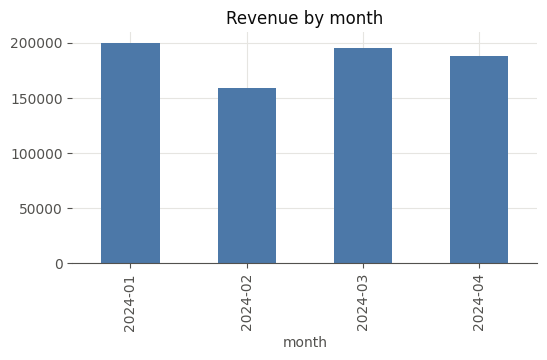

In [624]:
q1["revenue"].plot(kind="bar", color="#4C78A8", figsize=(6, 3))
plt.title("Revenue by month")
plt.show()

In [625]:
daily = df.groupby("jd")["Price"].sum()          # إيراد كل يوم
print(daily.describe().round(0))                 # ملخص سريع

by_weekday = daily.groupby(daily.index.day_name()).mean().round(0).sort_values(ascending=False)
print(by_weekday)

count     121.0
mean     6132.0
std      1132.0
min      1562.0
25%      5546.0
50%      6227.0
75%      7003.0
max      9196.0
Name: Price, dtype: float64
jd
Wednesday    6694.0
Tuesday      6260.0
Friday       6202.0
Thursday     6191.0
Monday       5987.0
Sunday       5885.0
Saturday     5702.0
Name: Price, dtype: float64


In [626]:
top10 = df.groupby("route")["Price"].sum().sort_values(ascending=False).head(10)
print(top10)

route
London Kings Cross -> York                        183193
Liverpool Lime Street -> London Euston            113299
London Paddington -> Reading                       65368
London Euston -> Manchester Piccadilly             61004
London St Pancras -> Birmingham New Street         52869
London Euston -> Birmingham New Street             50349
Manchester Piccadilly -> London Euston             33860
Birmingham New Street -> London St Pancras         19011
Manchester Piccadilly -> Liverpool Lime Street     17310
Manchester Piccadilly -> London Paddington         16432
Name: Price, dtype: int64


In [627]:
s = df.groupby("Departure Station")["Price"].sum()
print((s / s.sum() * 100).sort_values(ascending=False).round(1))

Departure Station
London Kings Cross       26.9
Liverpool Lime Street    18.2
London Euston            15.1
London Paddington        11.3
Manchester Piccadilly    10.2
London St Pancras         8.5
Birmingham New Street     5.1
York                      2.6
Reading                   1.4
Oxford                    0.4
Edinburgh Waverley        0.3
Bristol Temple Meads      0.0
Name: Price, dtype: float64


In [628]:
q5 = df.groupby("Ticket Type")["Price"].agg(tickets="size", revenue="sum")
q5["ticket_share_%"]  = (q5["tickets"] / q5["tickets"].sum() * 100).round(1)
q5["revenue_share_%"] = (q5["revenue"] / q5["revenue"].sum() * 100).round(1)
print(q5)

             tickets  revenue  ticket_share_%  revenue_share_%
Ticket Type                                                   
Advance        17561   309274            55.5             41.7
Anytime         5340   209309            16.9             28.2
Off-Peak        8752   223338            27.6             30.1


In [629]:
q6 = df.groupby("Ticket Class")["Price"].agg(tickets="size", revenue="sum", avg_price="mean").round(1)
print(q6)

              tickets  revenue  avg_price
Ticket Class                             
First Class      3058   149399       48.9
Standard        28595   592522       20.7


In [630]:
q7 = df.groupby("Railcard")["Price"].agg(tickets="size", avg_price="mean").round(1)
print(q7.sort_values("tickets", ascending=False))

          tickets  avg_price
Railcard                    
Adult        4846       17.8
Disabled     3089       16.9
Senior       2800       10.6


In [631]:
top = df["route"].value_counts().head(10).index
x = df[df["route"].isin(top)].groupby(["route", "Ticket Type"]).size().unstack(fill_value=0)
x["dominant"] = x.idxmax(axis=1)
print(x.loc[top])

Ticket Type                                     Advance  Anytime  Off-Peak  \
route                                                                        
Manchester Piccadilly -> Liverpool Lime Street     2635      749      1244   
London Euston -> Birmingham New Street             2308      622      1279   
London Kings Cross -> York                         2158      710      1054   
London Paddington -> Reading                       2126      576      1171   
London St Pancras -> Birmingham New Street         1937      524      1010   
Liverpool Lime Street -> Manchester Piccadilly     1815      244       943   
Liverpool Lime Street -> London Euston              566      334       197   
London Euston -> Manchester Piccadilly              384      148       180   
Birmingham New Street -> London St Pancras          395      156       151   
London Paddington -> Oxford                         251      180        54   

Ticket Type                                    dominant  
route

In [632]:
print(df["route"].value_counts().head(10))

route
Manchester Piccadilly -> Liverpool Lime Street    4628
London Euston -> Birmingham New Street            4209
London Kings Cross -> York                        3922
London Paddington -> Reading                      3873
London St Pancras -> Birmingham New Street        3471
Liverpool Lime Street -> Manchester Piccadilly    3002
Liverpool Lime Street -> London Euston            1097
London Euston -> Manchester Piccadilly             712
Birmingham New Street -> London St Pancras         702
London Paddington -> Oxford                        485
Name: count, dtype: int64


dep_hour
18    3113
6     3112
17    2888
7     2795
16    2301
8     2179
Name: count, dtype: int64


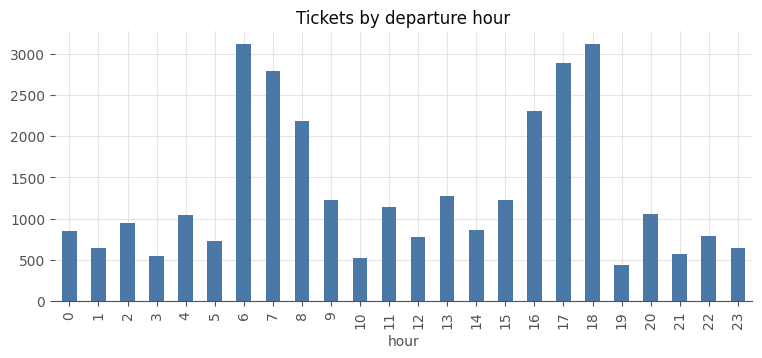

In [633]:
df["dep_hour"] = pd.to_datetime(df["Departure Time"], format="%H:%M:%S").dt.hour

h = df["dep_hour"].value_counts().sort_index()
print(h.sort_values(ascending=False).head(6))

h.plot(kind="bar", color="#4C78A8", figsize=(9, 3.5))
plt.title("Tickets by departure hour")
plt.xlabel("hour")
plt.show()

In [634]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(df.groupby("weekday").size().reindex(order))

df["is_weekend"] = df["jd"].dt.dayofweek >= 5          # 5 = السبت، 6 = الأحد
d = df.groupby(["jd", "is_weekend"]).size().reset_index(name="n")
print(d.groupby("is_weekend")["n"].mean().round(0))

weekday
Monday       4436
Tuesday      4607
Wednesday    4692
Thursday     4580
Friday       4351
Saturday     4407
Sunday       4580
dtype: int64
is_weekend
False    261.0
True     264.0
Name: n, dtype: float64


In [635]:
print(df["Departure Station"].value_counts().head(5))
print(df["Arrival Destination"].value_counts().head(5))

Departure Station
Manchester Piccadilly    5650
London Euston            4954
Liverpool Lime Street    4561
London Paddington        4500
London Kings Cross       4229
Name: count, dtype: int64
Arrival Destination
Birmingham New Street    7742
Liverpool Lime Street    5022
York                     4019
Manchester Piccadilly    3968
Reading                  3920
Name: count, dtype: int64


In [636]:
def mins(a, b):
    d = (pd.to_datetime(b, format="%H:%M:%S") - pd.to_datetime(a, format="%H:%M:%S")).dt.total_seconds() / 60
    return d.where(d >= -600, d + 1440)

In [637]:
df["delay_min"] = mins(df["Arrival Time"], df["Actual Arrival Time"])
df["delayed"]   = df["Journey Status"] == "Delayed"
df["cancelled"] = df["Journey Status"] == "Cancelled"
df["disrupted"] = df["Journey Status"] != "On Time"

In [638]:
def rates(by, data=None):
    d = df if data is None else data
    g = d.groupby(by).agg(tickets=("Price", "size"), delayed_pct=("delayed", "mean"), cancelled_pct=("cancelled", "mean"))
    g[["delayed_pct", "cancelled_pct"]] *= 100
    return g.round(1)

In [639]:
print((df["Journey Status"].value_counts(normalize=True) * 100).round(1))

Journey Status
On Time      86.8
Delayed       7.2
Cancelled     5.9
Name: proportion, dtype: float64


In [640]:
st = rates("Departure Station")
print(st[st["tickets"] >= 100].sort_values("delayed_pct", ascending=False))

rt = rates("route")
rt["disrupted_pct"] = rt["delayed_pct"] + rt["cancelled_pct"]
print(rt[rt["tickets"] >= 200].sort_values("disrupted_pct", ascending=False).head(10))

                       tickets  delayed_pct  cancelled_pct
Departure Station                                         
Liverpool Lime Street     4561         19.7            5.1
Manchester Piccadilly     5650         11.9            5.6
Oxford                     144         10.4            4.2
Birmingham New Street     2136          6.6            6.0
York                       927          6.3            6.1
London Euston             4954          5.2            5.2
London Kings Cross        4229          3.1            4.9
London Paddington         4500          1.5            7.9
London St Pancras         3891          0.0            7.5
Reading                    594          0.0            4.9
                                                tickets  delayed_pct  \
route                                                                  
Liverpool Lime Street -> London Euston             1097         71.1   
Manchester Piccadilly -> London Euston              345         69.6   
Birm

In [641]:
print(df.loc[df["disrupted"], "Reason for Delay"].value_counts())

Reason for Delay
Weather               995
Signal Failure        970
Technical Issue       707
Staffing              410
Staff Shortage        399
Weather Conditions    377
Traffic               314
Name: count, dtype: int64


In [642]:
d = df[df["delayed"]]
print(d["delay_min"].describe().round(1))

h = d.groupby("dep_hour")["delay_min"].agg(n="size", avg="mean").round(1)
print(h[h["n"] >= 20])

count    2292.0
mean       42.2
std        34.5
min         0.0
25%        19.0
50%        37.0
75%        53.0
max       180.0
Name: delay_min, dtype: float64
            n   avg
dep_hour           
3         125  24.0
5          37  29.0
6          74  39.9
8         728  41.6
9         221  69.1
11        300  53.4
15        143  21.4
16        206  57.0
17        381  30.2


In [643]:
df["refund"] = df["Refund Request"] == "Yes"

In [644]:
print(f"Refund requests: {df['refund'].sum()} of {len(df)} journeys = {df['refund'].mean():.2%}")

Refund requests: 1118 of 31653 journeys = 3.53%


In [645]:
print((df.groupby("Journey Status")["refund"].mean() * 100).round(1))

Journey Status
Cancelled    30.4
Delayed      23.8
On Time       0.0
Name: refund, dtype: float64


In [646]:
print(df[df["refund"]].groupby("Reason for Delay").size().sort_values(ascending=False))

print((df[df["disrupted"]].groupby("Reason for Delay")["refund"].mean() * 100).round(1).sort_values(ascending=False))

Reason for Delay
Technical Issue       388
Signal Failure        215
Staffing              182
Traffic               121
Staff Shortage         79
Weather                69
Weather Conditions     64
dtype: int64
Reason for Delay
Technical Issue       54.9
Staffing              44.4
Traffic               38.5
Signal Failure        22.2
Staff Shortage        19.8
Weather Conditions    17.0
Weather                6.9
Name: refund, dtype: float64


In [647]:
risk = df[df["cancelled"] | df["refund"]]
print("Revenue at risk:", risk["Price"].sum(), f"= {risk['Price'].sum() / df['Price'].sum():.1%} of total revenue")
print(risk.groupby("Journey Status")["Price"].agg(["size", "sum"]))

Revenue at risk: 71621 = 9.7% of total revenue
                size    sum
Journey Status             
Cancelled       1880  45456
Delayed          546  26165


In [648]:
m = df.groupby("month").agg(tickets=("Price", "size"), revenue=("Price", "sum"))
m["avg_price"]      = m["revenue"] / m["tickets"]
m["revenue_change"] = m["revenue"].diff()                          # الفرق عن الشهر اللي قبله
m["volume_effect"]  = m["tickets"].diff() * m["avg_price"].shift() # (T1-T0) * P0
m["price_effect"]   = m["avg_price"].diff() * m["tickets"]         # (P1-P0) * T1
print(m.round(1))

         tickets  revenue  avg_price  revenue_change  volume_effect  \
month                                                                 
2024-01     8111   199618       24.6             NaN            NaN   
2024-02     7644   159374       20.8        -40244.0       -11493.2   
2024-03     8117   195147       24.0         35773.0         9861.8   
2024-04     7781   187782       24.1         -7365.0        -8078.0   

         price_effect  
month                  
2024-01           NaN  
2024-02      -28750.8  
2024-03       25911.2  
2024-04         713.0  


In [649]:
rev = df.groupby("route")["Price"].sum().sort_values(ascending=False).reset_index()
rev["cum_share"] = rev["Price"].cumsum() / rev["Price"].sum()      # النسبة التراكمية

top20 = int(len(rev) * 0.2)
print(f"Routes: {len(rev)} | top 20% = {top20} routes -> {rev.loc[:top20-1, 'Price'].sum() / rev['Price'].sum():.1%} of revenue")
print("Routes needed for 80% of revenue:", (rev["cum_share"] < 0.8).sum() + 1)

Routes: 65 | top 20% = 13 routes -> 87.4% of revenue
Routes needed for 80% of revenue: 9


In [650]:
t = df[df["delayed"]].groupby("Reason for Delay")["delay_min"].agg(
    delays="size", avg_min="mean", median_min="median", max_min="max").round(1)
print(t.sort_values("avg_min", ascending=False))

                    delays  avg_min  median_min  max_min
Reason for Delay                                        
Staff Shortage         183     74.9        50.0    179.0
Signal Failure         451     51.8        37.0    180.0
Weather                758     46.8        48.0     99.0
Traffic                 87     32.3        26.0     89.0
Weather Conditions     169     30.5        29.0     69.0
Staffing               172     25.9        20.5     88.0
Technical Issue        472     24.9        24.0     80.0


In [651]:
d = df[df["delayed"]].copy()
d["delay_bucket"] = pd.cut(d["delay_min"], [-1, 15, 30, 45, 60, 90, 200])
print(d.groupby("delay_bucket", observed=True).agg(journeys=("refund", "size"), refund_rate=("refund", "mean")).round(3))
print("corr(delay_min, refund):", round(d["delay_min"].corr(d["refund"].astype(int)), 3))

              journeys  refund_rate
delay_bucket                       
(-1, 15]           450        0.458
(15, 30]           505        0.461
(30, 45]           531        0.181
(45, 60]           483        0.023
(60, 90]           140        0.000
(90, 200]          183        0.000
corr(delay_min, refund): -0.36


In [652]:
c = df[df["cancelled"]]
print(f"Cancelled: {len(c)} | with refund request: {c['refund'].sum()} ({c['refund'].mean():.1%}) | without: {(~c['refund']).sum()} ({(~c['refund']).mean():.1%})")
print("Revenue of cancelled journeys with no refund request:", c[~c["refund"]]["Price"].sum())

Cancelled: 1880 | with refund request: 572 (30.4%) | without: 1308 (69.6%)
Revenue of cancelled journeys with no refund request: 32919


In [653]:
r = df.groupby("route").agg(tickets=("Price", "size"), revenue=("Price", "sum"), disruption_rate=("disrupted", "mean"))
top = r.sort_values("revenue", ascending=False).head(15).copy()
top["disruption_rate"] = (top["disruption_rate"] * 100).round(1)

avg = df["disrupted"].mean() * 100
top["above_network_avg"] = top["disruption_rate"] > avg
print(f"Network disruption rate: {avg:.1f}%")
print(top)

Network disruption rate: 13.2%
                                                tickets  revenue  \
route                                                              
London Kings Cross -> York                         3922   183193   
Liverpool Lime Street -> London Euston             1097   113299   
London Paddington -> Reading                       3873    65368   
London Euston -> Manchester Piccadilly              712    61004   
London St Pancras -> Birmingham New Street         3471    52869   
London Euston -> Birmingham New Street             4209    50349   
Manchester Piccadilly -> London Euston              345    33860   
Birmingham New Street -> London St Pancras          702    19011   
Manchester Piccadilly -> Liverpool Lime Street     4628    17310   
Manchester Piccadilly -> London Paddington          144    16432   
London Paddington -> Oxford                         485    12859   
Liverpool Lime Street -> Manchester Piccadilly     3002    11950   
York -> Peterboro

In [654]:
df["lead_days"] = (df["jd"] - pd.to_datetime(df["Date of Purchase"])).dt.days   # عدد الأيام بين الشراء والرحلة

print(df["lead_days"].describe().round(1))
print(df.groupby(pd.cut(df["lead_days"], [-1, 0, 1, 3, 7, 14, 30]), observed=True)["Price"].agg(tickets="size", avg_price="mean").round(1))
print("corr(lead_days, price):", round(df["lead_days"].corr(df["Price"]), 3))

count    31653.0
mean         1.7
std          3.9
min          0.0
25%          0.0
50%          1.0
75%          1.0
max         28.0
Name: lead_days, dtype: float64
           tickets  avg_price
lead_days                    
(-1, 0]      14092       30.7
(0, 1]       13744       17.6
(1, 3]         651       18.0
(3, 7]         940       17.0
(7, 14]       1256       17.2
(14, 30]       970       18.7
corr(lead_days, price): -0.081


In [655]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

MAY = pd.date_range("2024-05-01", "2024-05-31")

def design(idx, t0):
    X = pd.get_dummies(pd.Series(pd.Categorical(idx.dayofweek, categories=range(7)), index=idx)).astype(int)
    X.columns = [f"dow{c}" for c in X.columns]       # عمود لكل يوم أسبوع
    X["t"] = (idx - t0).days                          # الاتجاه العام
    return X

def fit_forecast(series, horizon=MAY, holdout=28):
    t0 = series.index[0]; X = design(series.index, t0)
    m = Ridge(alpha=1.0).fit(X.iloc[:-holdout], series.iloc[:-holdout])
    mae   = mean_absolute_error(series.iloc[-holdout:], m.predict(X.iloc[-holdout:]))
    naive = mean_absolute_error(series.iloc[-holdout:], series.shift(7).iloc[-holdout:])
    m = Ridge(alpha=1.0).fit(X, series)
    resid = (series - m.predict(X)).std()
    fc = pd.Series(m.predict(design(horizon, t0)), index=horizon).clip(lower=0)
    return fc, mae, naive, resid

daily = df.groupby("jd").size().reindex(pd.date_range(df["jd"].min(), df["jd"].max()), fill_value=0)
fc, mae, naive, sd = fit_forecast(daily)
print(f"Forecast journeys May 2024: {fc.sum():,.0f}  (95% interval about +/- {1.96 * sd * np.sqrt(len(fc)):,.0f})")
print(f"Holdout MAE: model {mae:.1f} vs same-day-last-week {naive:.1f} tickets/day")

Forecast journeys May 2024: 8,304  (95% interval about +/- 423)
Holdout MAE: model 21.9 vs same-day-last-week 32.4 tickets/day


Forecast revenue May 2024: 195,893 | holdout MAE model 880 vs naive 991
2024-05-29    6862.0
2024-05-22    6846.0
2024-05-15    6831.0
2024-05-08    6816.0
2024-05-01    6800.0
dtype: float64


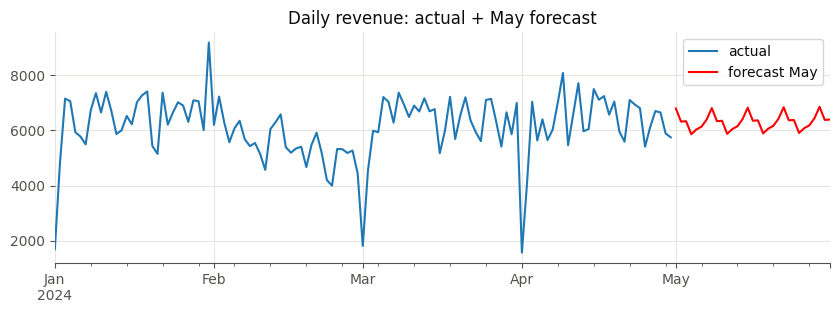

In [656]:
rev_daily = df.groupby("jd")["Price"].sum().reindex(pd.date_range(df["jd"].min(), df["jd"].max()), fill_value=0)
fcr, mae_r, naive_r, _ = fit_forecast(rev_daily)

print(f"Forecast revenue May 2024: {fcr.sum():,.0f} | holdout MAE model {mae_r:.0f} vs naive {naive_r:.0f}")
print(fcr.sort_values(ascending=False).head(5).round(0))

rev_daily.plot(figsize=(10, 3), label="actual"); fcr.plot(label="forecast May", color="red")
plt.legend(); plt.title("Daily revenue: actual + May forecast"); plt.show()
fcr.round(0).to_csv("forecast_may_daily_revenue.csv", header=["forecast_revenue"])

In [657]:

rows = []
full = pd.date_range(df["jd"].min(), df["jd"].max())
for cls, typ in product(df["Ticket Class"].unique(), df["Ticket Type"].unique()):
    s = df[(df["Ticket Class"] == cls) & (df["Ticket Type"] == typ)].groupby("jd").size().reindex(full, fill_value=0)
    f, *_ = fit_forecast(s)
    rows.append({"class": cls, "ticket_type": typ, "Jan-Apr/day": round(s.mean(), 1), "May total": round(f.sum()), "May/day": round(f.mean(), 1)})
print(pd.DataFrame(rows).sort_values("May total", ascending=False).to_string(index=False))

      class ticket_type  Jan-Apr/day  May total  May/day
   Standard     Advance        130.6       3921    126.5
   Standard    Off-Peak         65.7       2204     71.1
   Standard     Anytime         40.1       1353     43.6
First Class     Advance         14.6        426     13.8
First Class    Off-Peak          6.6        244      7.9
First Class     Anytime          4.0        155      5.0


In [658]:
full = pd.date_range(df["jd"].min(), df["jd"].max())
dis      = df.groupby("jd")["disrupted"].sum().reindex(full, fill_value=0)
risk_rev = df[df["cancelled"] | df["refund"]].groupby("jd")["Price"].sum().reindex(full, fill_value=0)

f_dis, *_  = fit_forecast(dis)
f_risk, *_ = fit_forecast(risk_rev)
print(f"May: disrupted journeys ~ {f_dis.sum():,.0f} (avg per 31 days Jan-Apr: {dis.mean() * 31:,.0f})")
print(f"May: revenue at risk ~ {f_risk.sum():,.0f} (avg per 31 days Jan-Apr: {risk_rev.mean() * 31:,.0f})")

May: disrupted journeys ~ 1,121 (avg per 31 days Jan-Apr: 1,069)
May: revenue at risk ~ 17,961 (avg per 31 days Jan-Apr: 18,349)


In [659]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

feat = ["route", "dep_hour", "weekday", "Ticket Type", "Ticket Class", "Purchase Type", "Price", "lead_days"]
y = df["disrupted"].astype(int)
Xtr, Xte, ytr, yte = train_test_split(df[feat], y, test_size=0.25, random_state=42, stratify=y)

pre = ColumnTransformer([
    ("te",  TargetEncoder(cv=5, random_state=42), ["route"]),                       # الخط: 65 قيمة
    ("oh",  OneHotEncoder(handle_unknown="ignore"), ["weekday", "Ticket Type", "Ticket Class", "Purchase Type"]),
    ("num", "passthrough", ["dep_hour", "Price", "lead_days"])])
model = make_pipeline(pre, HistGradientBoostingClassifier(max_depth=3, random_state=42)).fit(Xtr, ytr)

p = model.predict_proba(Xte)[:, 1]
top10 = pd.Series(yte.values)[np.argsort(-p)[: len(p) // 10]].mean()
print(f"Base rate: {y.mean():.1%} | test AUC = {roc_auc_score(yte, p):.3f} (0.5 = random)")
print(f"Precision in highest-risk 10%: {top10:.1%}")

Base rate: 13.2% | test AUC = 0.799 (0.5 = random)
Precision in highest-risk 10%: 61.1%


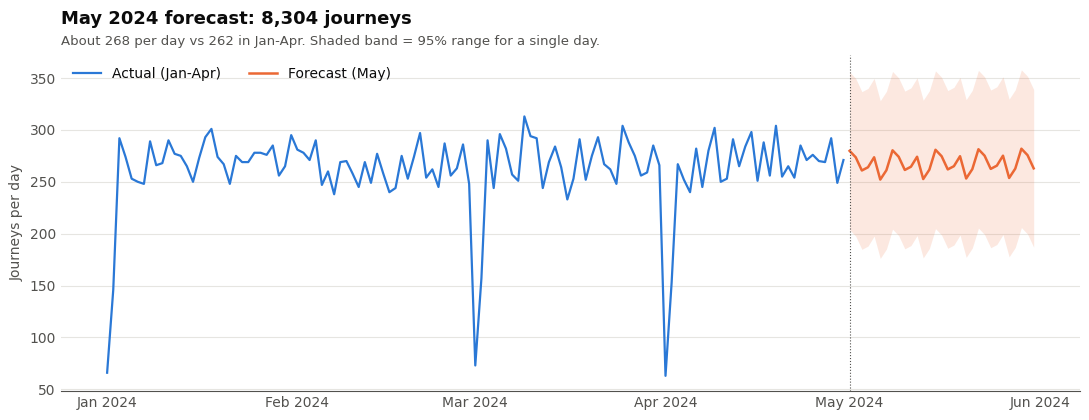

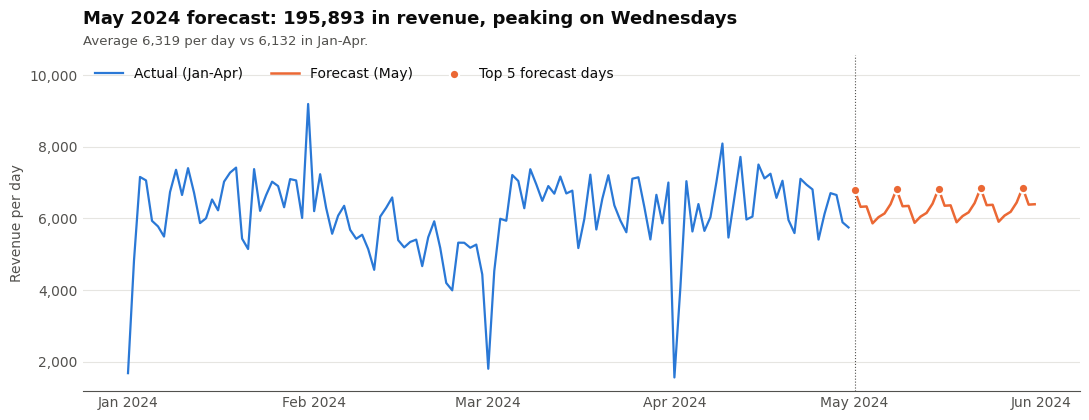

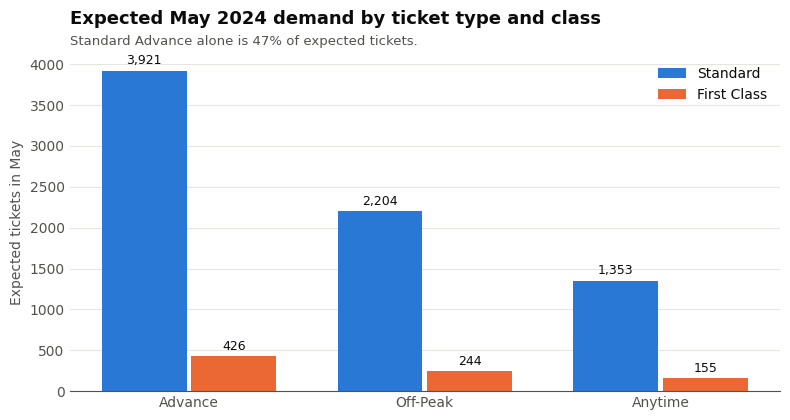

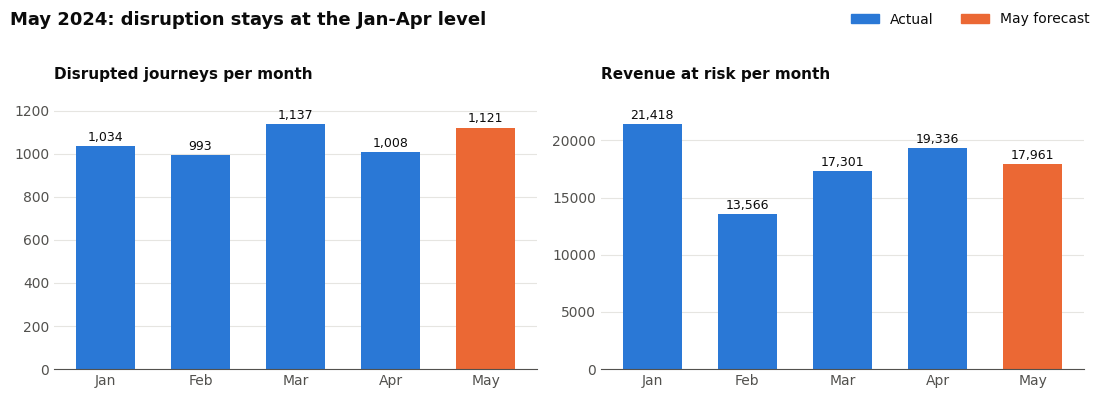

Saved: fig1_forecast_journeys.png, fig2_forecast_revenue.png, fig3_forecast_demand_by_class.png, fig4_forecast_disruption.png


In [660]:

# ---------- Style (one place) ----------
BLUE, ORANGE = "#2a78d6", "#eb6834"          # blue = actual, orange = forecast
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.facecolor": "white", "axes.facecolor": "white"})

def style(ax, title, subtitle=None):
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=22 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5, color=MUTED, va="bottom")
    ax.tick_params(length=0)

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# ---------- Chart 1 (F1): daily journeys, actual + May forecast ----------
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.plot(daily.index, daily.values, color=BLUE, lw=1.6, label="Actual (Jan-Apr)")
ax.plot(fc.index, fc.values, color=ORANGE, lw=1.8, label="Forecast (May)")
ax.fill_between(fc.index, (fc - 1.96 * sd).clip(lower=0), fc + 1.96 * sd, color=ORANGE, alpha=0.15, lw=0)
ax.axvline(pd.Timestamp("2024-05-01"), color=MUTED, lw=0.8, ls=":")
style(ax, f"May 2024 forecast: {fc.sum():,.0f} journeys", f"About {fc.mean():.0f} per day vs {daily.mean():.0f} in Jan-Apr. Shaded band = 95% range for a single day.")
month_axis(ax); ax.set_ylabel("Journeys per day"); ax.legend(frameon=False, loc="upper left", ncol=2)
plt.tight_layout(); plt.savefig("fig1_forecast_journeys.png", dpi=150); plt.show()

# ---------- Chart 2 (F2): daily revenue, actual + May forecast ----------
peak5 = fcr.nlargest(5)
peak_day = peak5.index.day_name().value_counts().index[0]
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.plot(rev_daily.index, rev_daily.values, color=BLUE, lw=1.6, label="Actual (Jan-Apr)")
ax.plot(fcr.index, fcr.values, color=ORANGE, lw=1.8, label="Forecast (May)")
ax.scatter(peak5.index, peak5.values, color=ORANGE, s=45, zorder=3, edgecolor="white", linewidth=1.5, label="Top 5 forecast days")
ax.axvline(pd.Timestamp("2024-05-01"), color=MUTED, lw=0.8, ls=":")
style(ax, f"May 2024 forecast: {fcr.sum():,.0f} in revenue, peaking on {peak_day}s",
      f"Average {fcr.mean():,.0f} per day vs {rev_daily.mean():,.0f} in Jan-Apr.")
month_axis(ax); ax.set_ylabel("Revenue per day"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(top=rev_daily.max() * 1.15)   # headroom so the legend never touches the line
ax.legend(frameon=False, loc="upper left", ncol=3)
plt.tight_layout(); plt.savefig("fig2_forecast_revenue.png", dpi=150); plt.show()

# ---------- Chart 3 (F3): expected May demand by ticket type and class ----------
seg = pd.DataFrame(rows)
p = seg.pivot(index="ticket_type", columns="class", values="May total").loc[["Advance", "Off-Peak", "Anytime"]]
x = np.arange(len(p)); w = 0.36
fig, ax = plt.subplots(figsize=(8, 4.3))
b1 = ax.bar(x - w / 2 - 0.01, p["Standard"], w, color=BLUE, label="Standard")
b2 = ax.bar(x + w / 2 + 0.01, p["First Class"], w, color=ORANGE, label="First Class")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 40, f"{r.get_height():,.0f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(x); ax.set_xticklabels(p.index); ax.set_ylabel("Expected tickets in May")
style(ax, "Expected May 2024 demand by ticket type and class",
      f"Standard Advance alone is {p.loc['Advance', 'Standard'] / p.values.sum():.0%} of expected tickets.")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig("fig3_forecast_demand_by_class.png", dpi=150); plt.show()

# ---------- Chart 4 (F4): disrupted journeys and revenue at risk, monthly ----------
may_label = pd.Timestamp("2024-05-01")
m_dis = dis.resample("MS").sum(); m_dis.loc[may_label] = f_dis.sum()
m_risk = risk_rev.resample("MS").sum(); m_risk.loc[may_label] = f_risk.sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
for ax, s, title in [(axes[0], m_dis, "Disrupted journeys per month"), (axes[1], m_risk, "Revenue at risk per month")]:
    cols = [BLUE] * (len(s) - 1) + [ORANGE]
    bars = ax.bar([d.strftime("%b") for d in s.index], s.values, color=cols, width=0.62)
    for r in bars:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() * 1.01, f"{r.get_height():,.0f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold"); ax.tick_params(length=0)
    ax.set_ylim(0, s.max() * 1.15)
handles = [plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)]
fig.legend(handles, ["Actual", "May forecast"], frameon=False, loc="upper right", ncol=2)
fig.suptitle("May 2024: disruption stays at the Jan-Apr level", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.savefig("fig4_forecast_disruption.png", dpi=150); plt.show()
print("Saved: fig1_forecast_journeys.png, fig2_forecast_revenue.png, fig3_forecast_demand_by_class.png, fig4_forecast_disruption.png")

In [661]:
m = df.groupby("month").agg(tickets=("Price", "size"), revenue=("Price", "sum"))
m["avg_price"] = m.revenue / m.tickets
m["revenue_change"] = m.revenue.diff()
m["volume_effect"] = m.tickets.diff() * m.avg_price.shift()   # (t1-t0) * p0
m["price_effect"] = m.avg_price.diff() * m.tickets            # (p1-p0) * t1
print(m.round(1))
print("\nvolume_effect + price_effect = revenue_change (exact decomposition)")

         tickets  revenue  avg_price  revenue_change  volume_effect  \
month                                                                 
2024-01     8111   199618       24.6             NaN            NaN   
2024-02     7644   159374       20.8        -40244.0       -11493.2   
2024-03     8117   195147       24.0         35773.0         9861.8   
2024-04     7781   187782       24.1         -7365.0        -8078.0   

         price_effect  
month                  
2024-01           NaN  
2024-02      -28750.8  
2024-03       25911.2  
2024-04         713.0  

volume_effect + price_effect = revenue_change (exact decomposition)


In [662]:
r = df.groupby("route").agg(tickets=("Price", "size"), revenue=("Price", "sum"), avg_price=("Price", "mean"))
r["volume_rank"] = r.tickets.rank(ascending=False); r["revenue_rank"] = r.revenue.rank(ascending=False)
r["gap"] = r.volume_rank - r.revenue_rank
print("High revenue relative to volume (pricing power):\n", r.sort_values("gap", ascending=False).head(5).round(1))
print("\nHigh volume but weak revenue:\n", r.sort_values("gap").head(5).round(1))

High revenue relative to volume (pricing power):
                                             tickets  revenue  avg_price  \
route                                                                     
Liverpool Lime Street -> London St Pancras       31     3248      104.8   
London Paddington -> Manchester Piccadilly       30     2818       93.9   
Liverpool Lime Street -> London Paddington       27     2699      100.0   
Manchester Piccadilly -> London St Pancras       16     1593       99.6   
Reading -> Liverpool Lime Street                 16     1506       94.1   

                                            volume_rank  revenue_rank   gap  
route                                                                        
Liverpool Lime Street -> London St Pancras         47.0          20.0  27.0  
London Paddington -> Manchester Piccadilly         48.0          22.0  26.0  
Liverpool Lime Street -> London Paddington         49.0          24.0  25.0  
Manchester Piccadilly -> London St

weekday   Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  Sunday
dep_hour                                                                
0            115      119        121       141     104       134     119
1            100       79         83       104      93       102      83
2            133      125        136       132     130       131     155
3             65       76         81        95      69        77      80
4            126      153        143       162     143       166     148
5             97      121        106       114      91       103      93
6            458      453        452       455     442       417     435
7            386      416        411       361     396       399     426
8            302      302        335       319     323       304     294
9            180      187        149       189     179       164     182
10            61       82         66        88      81        72      75
11           146      157        177       165     

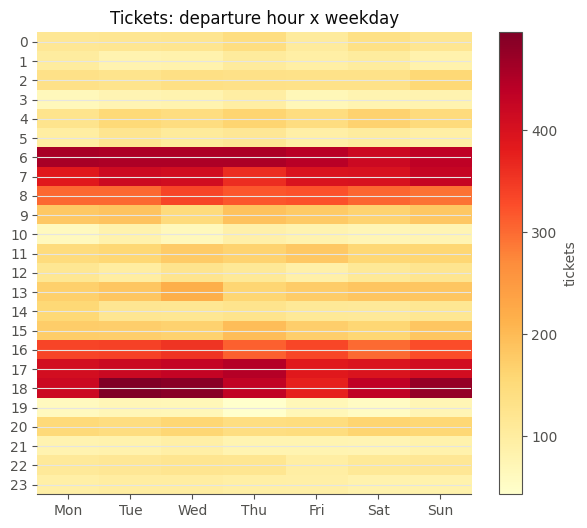

In [663]:
heat = df.pivot_table(index="dep_hour", columns="weekday", values="Price", aggfunc="size", fill_value=0)[order]
print(heat)
plt.figure(figsize=(7, 6)); plt.imshow(heat, aspect="auto", cmap="YlOrRd"); plt.colorbar(label="tickets")
plt.xticks(range(7), [d[:3] for d in order]); plt.yticks(range(24), heat.index); plt.title("Tickets: departure hour x weekday"); plt.show()

In [664]:
dep = df["Departure Station"].value_counts(); arr = df["Arrival Destination"].value_counts()
tr = pd.DataFrame({"departures": dep, "arrivals": arr}).fillna(0).astype(int)
tr["total_traffic"] = tr.departures + tr.arrivals
print(tr.sort_values("total_traffic", ascending=False).head(10))

                       departures  arrivals  total_traffic
Birmingham New Street        2136      7742           9878
Manchester Piccadilly        5650      3968           9618
Liverpool Lime Street        4561      5022           9583
London Euston                4954      1567           6521
York                          927      4019           4946
London Paddington            4500       351           4851
London St Pancras            3891       749           4640
Reading                       594      3920           4514
London Kings Cross           4229        84           4313
Oxford                        144       623            767


In [665]:
f = df.groupby(["Departure Station", "Arrival Destination"]).size().rename("forward").reset_index()
rv = f.rename(columns={"Departure Station": "Arrival Destination", "Arrival Destination": "Departure Station", "forward": "reverse"})
m = f.merge(rv, on=["Departure Station", "Arrival Destination"], how="left").fillna({"reverse": 0})
m["imbalance"] = m.forward - m.reverse
print(m.sort_values("imbalance", ascending=False).head(10).astype({"reverse": int}))
print("\nOne-way flows (no return tickets):", int((m.reverse == 0).sum()), "of", len(m), "directed pairs")

        Departure Station    Arrival Destination  forward  reverse  imbalance
24          London Euston  Birmingham New Street     4209      125     4084.0
30     London Kings Cross                   York     3922        0     3922.0
35      London Paddington                Reading     3873      148     3725.0
36      London St Pancras  Birmingham New Street     3471      702     2769.0
40  Manchester Piccadilly  Liverpool Lime Street     4628     3002     1626.0
19  Liverpool Lime Street          London Euston     1097        0     1097.0
34      London Paddington                 Oxford      485        0      485.0
25          London Euston  Manchester Piccadilly      712      345      367.0
37      London St Pancras              Leicester      337        0      337.0
58                   York                 Durham      258        0      258.0

One-way flows (no return tickets): 43 of 65 directed pairs


In [666]:
# Define the 'peak' column based on departure hours (e.g., peak hours are 7-9 and 16-18)
df["peak"] = df["dep_hour"].isin([7, 8, 9, 16, 17, 18]).map({True: "Peak", False: "Off-Peak"})

print("By hour:\n", rates("dep_hour"))
print("\nPeak vs off-peak:\n", rates("peak"))
print("\nWeekend vs weekday:\n", rates("is_weekend"))
print("\nBy weekday:\n", rates("weekday").reindex(order))

By hour:
           tickets  delayed_pct  cancelled_pct
dep_hour                                     
0             853          2.0            5.7
1             644          2.2            3.6
2             942          0.0            6.8
3             543         23.0            2.0
4            1041          1.5            4.4
5             725          5.1            3.0
6            3112          2.4            6.0
7            2795          0.5            9.1
8            2179         33.4            6.8
9            1230         18.0            3.7
10            525          0.0            3.2
11           1143         26.2            4.9
12            773          0.0            6.0
13           1276          0.0            4.9
14            855          1.8            4.9
15           1220         11.7            7.5
16           2301          9.0            4.5
17           2888         13.2            6.2
18           3113          0.0           10.0
19            438       

In [667]:
t = df[df.delayed].groupby("Reason for Delay").delay_min.agg(delays="size", avg_min="mean", median_min="median", max_min="max").round(1)
print(t.sort_values("avg_min", ascending=False))
print("\nMost frequent cause:", t.delays.idxmax(), "| longest average:", t.avg_min.idxmax())

                    delays  avg_min  median_min  max_min
Reason for Delay                                        
Staff Shortage         183     74.9        50.0    179.0
Signal Failure         451     51.8        37.0    180.0
Weather                758     46.8        48.0     99.0
Traffic                 87     32.3        26.0     89.0
Weather Conditions     169     30.5        29.0     69.0
Staffing               172     25.9        20.5     88.0
Technical Issue        472     24.9        24.0     80.0

Most frequent cause: Weather | longest average: Staff Shortage


In [668]:
x = df[df.disrupted].groupby(["route", "Reason for Delay"]).size().unstack(fill_value=0)
x["n"] = x.sum(axis=1)
reasons = [c for c in x.columns if c != "n"]
x["top_reason"] = x[reasons].idxmax(axis=1)
x["top_share_%"] = (x[reasons].max(axis=1) / x.n * 100).round(1)
print("Overall top-reason share:", round(df[df.disrupted]["Reason for Delay"].value_counts(normalize=True).iloc[0] * 100, 1), "%")
print(x[x.n >= 40].sort_values("top_share_%", ascending=False)[["n", "top_reason", "top_share_%"]].head(10))

Overall top-reason share: 23.8 %
Reason for Delay                                  n          top_reason  \
route                                                                     
Edinburgh Waverley -> London Kings Cross         51            Staffing   
Manchester Piccadilly -> Leeds                   65      Signal Failure   
Birmingham New Street -> Manchester Piccadilly  114     Technical Issue   
Birmingham New Street -> London Euston           49             Weather   
Liverpool Lime Street -> London Euston          879             Weather   
Liverpool Lime Street -> Manchester Piccadilly  231     Technical Issue   
London Kings Cross -> York                      329      Signal Failure   
London Euston -> Birmingham New Street          453      Signal Failure   
London St Pancras -> Birmingham New Street      273      Signal Failure   
Manchester Piccadilly -> London Euston          243  Weather Conditions   

Reason for Delay                                top_share_%  
rout

In [669]:
c = df[df.cancelled]
print("Cancellations by weekday:\n", c.groupby("weekday").size().reindex(order))
print("\nTop hours:", c.groupby("dep_hour").size().sort_values(ascending=False).head(5).to_dict())
rt = rates("route")
print("\nRoutes with highest cancellation rate (>=200 tickets):\n", rt[rt.tickets >= 200].sort_values("cancelled_pct", ascending=False).head(5))
dc = c.groupby("jd").size()
print("\nWorst days:\n", dc.sort_values(ascending=False).head(5), "\nDaily cancellations mean/std:", round(dc.mean(), 1), round(dc.std(), 1))

Cancellations by weekday:
 weekday
Monday       255
Tuesday      296
Wednesday    289
Thursday     242
Friday       211
Saturday     290
Sunday       297
dtype: int64

Top hours: {18: 311, 7: 254, 6: 187, 17: 179, 8: 148}

Routes with highest cancellation rate (>=200 tickets):
                                                 tickets  delayed_pct  \
route                                                                  
London Paddington -> Oxford                         485          0.0   
York -> Peterborough                                242          0.0   
Liverpool Lime Street -> London Euston             1097         71.1   
Birmingham New Street -> Manchester Piccadilly      224         42.9   
London St Pancras -> Birmingham New Street         3471          0.0   

                                                cancelled_pct  
route                                                          
London Paddington -> Oxford                              13.0  
York -> Peterborough    

In [670]:
for col in ["Ticket Class", "Ticket Type", "Railcard"]:
    print(f"\nRefund rate by {col} (%), all journeys vs disrupted only:")
    print(pd.DataFrame({"all": df.groupby(col).refund.mean() * 100, "disrupted_only": df[df.disrupted].groupby(col).refund.mean() * 100}).round(2))


Refund rate by Ticket Class (%), all journeys vs disrupted only:
               all  disrupted_only
Ticket Class                      
First Class   3.70           27.10
Standard      3.51           26.76

Refund rate by Ticket Type (%), all journeys vs disrupted only:
              all  disrupted_only
Ticket Type                      
Advance      3.48           27.13
Anytime      2.58           16.22
Off-Peak     4.22           34.52

Refund rate by Railcard (%), all journeys vs disrupted only:
           all  disrupted_only
Railcard                      
Adult     8.71           47.63
Disabled  1.94           18.40
Senior    4.29           43.17


In [671]:
loss = df[df.cancelled | df.refund]
print("Revenue at risk:", loss.Price.sum(), f"= {loss.Price.sum() / df.Price.sum():.1%} of revenue")
print("\nBy cause:\n", loss.groupby("Reason for Delay").Price.agg(tickets="size", revenue_at_risk="sum").sort_values("revenue_at_risk", ascending=False))
print("\nBy status:\n", loss.groupby("Journey Status").Price.sum())

Revenue at risk: 71621 = 9.7% of revenue

By cause:
                     tickets  revenue_at_risk
Reason for Delay                            
Technical Issue         551            18185
Staffing                348            13881
Signal Failure          579            13787
Traffic                 274             8420
Weather                 237             7168
Staff Shortage          229             6092
Weather Conditions      208             4088

By status:
 Journey Status
Cancelled    45456
Delayed      26165
Name: Price, dtype: int64


In [672]:
print("Lead time days:", df.lead_days.describe().round(1).to_dict())
print(df.groupby(pd.cut(df.lead_days, [-1, 0, 1, 3, 7, 14, 30]), observed=True).Price.agg(tickets="size", avg_price="mean").round(1))
print("corr(lead_days, price):", round(df.lead_days.corr(df.Price), 3))
print(df.groupby(["Ticket Type", df.lead_days.eq(0)]).Price.mean().unstack().round(1).rename(columns={False: "booked ahead", True: "same day"}))
print("Note: in this data every Advance ticket is booked 1+ days ahead and every Anytime/Off-Peak ticket is bought same day,")
print("so the same-day premium is really the ticket-type price difference (lead time and ticket type overlap).")

Lead time days: {'count': 31653.0, 'mean': 1.7, 'std': 3.9, 'min': 0.0, '25%': 0.0, '50%': 1.0, '75%': 1.0, 'max': 28.0}
           tickets  avg_price
lead_days                    
(-1, 0]      14092       30.7
(0, 1]       13744       17.6
(1, 3]         651       18.0
(3, 7]         940       17.0
(7, 14]       1256       17.2
(14, 30]       970       18.7
corr(lead_days, price): -0.081
lead_days    booked ahead  same day
Ticket Type                        
Advance              17.6       NaN
Anytime               NaN      39.2
Off-Peak              NaN      25.5
Note: in this data every Advance ticket is booked 1+ days ahead and every Anytime/Off-Peak ticket is bought same day,
so the same-day premium is really the ticket-type price difference (lead time and ticket type overlap).


In [673]:
print((pd.crosstab(df["Ticket Type"], df["Purchase Type"], normalize="index") * 100).round(1))
print((pd.crosstab(df["Ticket Class"], df["Purchase Type"], normalize="index") * 100).round(1))

Purchase Type  Online  Station
Ticket Type                   
Advance          58.9     41.1
Anytime          62.4     37.6
Off-Peak         55.4     44.6
Purchase Type  Online  Station
Ticket Class                  
First Class      58.2     41.8
Standard         58.5     41.5


In [674]:
print(df.groupby("Payment Method").Price.agg(tickets="size", total_value="sum", avg_value="mean").round(1))
print("\nBy channel:\n", df.groupby("Purchase Type").Price.agg(tickets="size", total_value="sum", avg_value="mean").round(1))

                tickets  total_value  avg_value
Payment Method                                 
Contactless       10834       219444       20.3
Credit Card       19136       469511       24.5
Debit Card         1683        52966       31.5

By channel:
                tickets  total_value  avg_value
Purchase Type                                 
Online           18521       382754       20.7
Station          13132       359167       27.4


In [675]:

X = pd.DataFrame({"online": (df["Purchase Type"] == "Online").astype(int), "lead_log": np.log1p(df.lead_days),
                  "price_log": np.log1p(df.Price), "first": (df["Ticket Class"] == "First Class").astype(int),
                  "railcard": (df.Railcard != "No Railcard").astype(int)})
X = pd.concat([X, pd.get_dummies(df["Ticket Type"]).astype(int)], axis=1)
df["segment"] = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(StandardScaler().fit_transform(X))
prof = df.groupby("segment").agg(tickets=("Price", "size"), avg_price=("Price", "mean"), online=("Purchase Type", lambda s: (s == "Online").mean()),
                                 avg_lead_days=("lead_days", "mean"), first_class=("Ticket Class", lambda s: (s == "First Class").mean()),
                                 railcard=("Railcard", lambda s: (s != "No Railcard").mean()))
print(prof.round(2)); print(df.groupby("segment")["Ticket Type"].value_counts(normalize=True).unstack().round(2))

         tickets  avg_price  online  avg_lead_days  first_class  railcard
segment                                                                  
0          15797      15.34    0.59           3.00          0.0       1.0
1           7948      22.48    0.55           0.00          0.0       1.0
2           3058      48.86    0.58           1.63          1.0       1.0
3           4850      35.35    0.63           0.00          0.0       1.0
Ticket Type  Advance  Anytime  Off-Peak
segment                                
0               1.00      NaN       NaN
1                NaN      NaN      1.00
2               0.58     0.16      0.26
3                NaN     1.00       NaN


Routes: 65 | top 20% = 13 routes -> 87.4% of revenue
Routes needed for 80% of revenue: 9


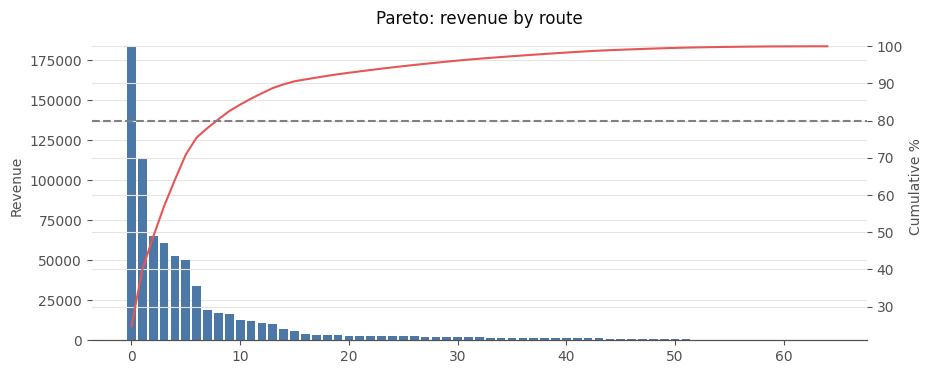

In [676]:
rev = df.groupby("route").Price.sum().sort_values(ascending=False).reset_index()
rev["cum_share"] = rev.Price.cumsum() / rev.Price.sum()
top20 = int(len(rev) * 0.2)
print(f"Routes: {len(rev)} | top 20% = {top20} routes -> {rev.loc[:top20 - 1, 'Price'].sum() / rev.Price.sum():.1%} of revenue")
print("Routes needed for 80% of revenue:", (rev.cum_share < 0.8).sum() + 1)
fig, ax = plt.subplots(figsize=(10, 4)); ax.bar(range(len(rev)), rev.Price, color="#4C78A8"); ax.set_ylabel("Revenue")
ax2 = ax.twinx(); ax2.plot(range(len(rev)), rev.cum_share * 100, color="#E45756"); ax2.axhline(80, ls="--", color="gray"); ax2.set_ylabel("Cumulative %")
ax.set_title("Pareto: revenue by route"); plt.show()

Days with |z|>2: 4 of 121
            revenue     z    weekday
jd                                  
2024-01-01     1682 -3.93     Monday
2024-01-31     9196  2.71  Wednesday
2024-03-01     1805 -3.82     Friday
2024-04-01     1562 -4.04     Monday
Tickets per day: min 63 max 313


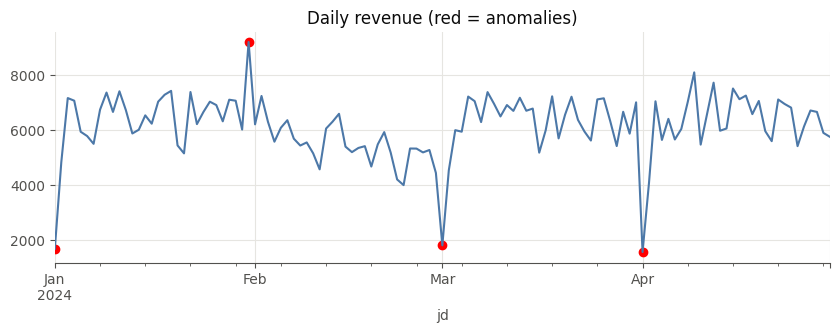

In [677]:
daily = df.groupby("jd").Price.sum()
z = (daily - daily.mean()) / daily.std()
out = daily[z.abs() > 2]
print(f"Days with |z|>2: {len(out)} of {len(daily)}")
print(pd.DataFrame({"revenue": out, "z": z[out.index].round(2), "weekday": out.index.day_name()}))
print("Tickets per day: min", df.groupby("jd").size().min(), "max", df.groupby("jd").size().max())
daily.plot(figsize=(10, 3), color="#4C78A8"); plt.scatter(out.index, out.values, color="red"); plt.title("Daily revenue (red = anomalies)"); plt.show()

In [678]:
df["first"] = df["Ticket Class"].eq("First Class")
print("First Class share peak vs off-peak:", df.groupby("peak")["first"].mean().round(3).to_dict())
fr = df.groupby("route").agg(tickets=("Price", "size"), first_share=("first", "mean"))
print("\nTop routes by First share (>=200 tickets):\n", fr[fr.tickets >= 200].sort_values("first_share", ascending=False).head(5).round(3))
risk = (df.cancelled | df.refund)
s = df.assign(risk_price=df.Price.where(risk, 0)).groupby("Ticket Class").agg(tickets=("Price", "size"), avg_price=("Price", "mean"), disrupted=("disrupted", "mean"), risk_price=("risk_price", "sum"), revenue=("Price", "sum"))
s["revenue_at_risk_%"] = s.risk_price / s.revenue * 100
print("\nProfitability vs disruption:\n", s.drop(columns=["risk_price"]).round(2))

First Class share peak vs off-peak: {'Off-Peak': 0.096, 'Peak': 0.098}

Top routes by First share (>=200 tickets):
                                             tickets  first_share
route                                                           
London Euston -> Manchester Piccadilly          712        0.119
Birmingham New Street -> London St Pancras      702        0.115
York -> Doncaster                               211        0.114
York -> Peterborough                            242        0.112
London Paddington -> Reading                   3873        0.106

Profitability vs disruption:
               tickets  avg_price  disrupted  revenue  revenue_at_risk_%
Ticket Class                                                           
First Class      3058      48.86       0.14   149399               9.03
Standard        28595      20.72       0.13   592522               9.81


In [679]:
print((pd.crosstab(df.Railcard, df["Ticket Type"], normalize="index") * 100).round(1))
print("\nShare of peak-hour travel by railcard (%):\n", (df.groupby("Railcard")["peak"].apply(lambda x: (x == "Peak").mean()) * 100).round(1))

Ticket Type  Advance  Anytime  Off-Peak
Railcard                               
Adult           55.9     16.7      27.3
Disabled        53.8     17.8      28.5
Senior          55.9     21.8      22.4

Share of peak-hour travel by railcard (%):
 Railcard
Adult       50.8
Disabled    33.9
Senior      51.7
Name: peak, dtype: float64


In [680]:
base = df[df.Railcard == "No Railcard"].groupby(["route", "Ticket Type"]).Price.mean().rename("base_price").reset_index()
h = df[df.Railcard != "No Railcard"].merge(base, on=["route", "Ticket Type"], how="left").dropna(subset=["base_price"])
h["gap"] = h.base_price - h.Price
print("ESTIMATE (no base fare in data): gap vs average no-railcard price on same route + ticket type")
print(h.groupby("Railcard").agg(tickets=("gap", "size"), avg_gap=("gap", "mean"), total_gap=("gap", "sum")).round(1))
print("Total estimated discount given:", round(h.gap.sum()), "=", f"{h.gap.sum() / df.Price.sum():.1%} of actual revenue")

ESTIMATE (no base fare in data): gap vs average no-railcard price on same route + ticket type
Empty DataFrame
Columns: [tickets, avg_gap, total_gap]
Index: []
Total estimated discount given: 0 = 0.0% of actual revenue


In [681]:
r = df.groupby("route").agg(tickets=("Price", "size"), disruption_rate=("disrupted", "mean"))
r = r[r.tickets >= 100]
print("Correlation (tickets vs disruption rate) across", len(r), "routes:", round(r.tickets.corr(r.disruption_rate), 3))
print((r.sort_values("tickets", ascending=False).head(10).assign(disruption_rate=lambda x: (x.disruption_rate * 100).round(1))))

Correlation (tickets vs disruption rate) across 34 routes: -0.049
                                                tickets  disruption_rate
route                                                                   
Manchester Piccadilly -> Liverpool Lime Street     4628             13.9
London Euston -> Birmingham New Street             4209             10.8
London Kings Cross -> York                         3922              8.4
London Paddington -> Reading                       3873              9.1
London St Pancras -> Birmingham New Street         3471              7.9
Liverpool Lime Street -> Manchester Piccadilly     3002              7.7
Liverpool Lime Street -> London Euston             1097             80.1
London Euston -> Manchester Piccadilly              712              6.3
Birmingham New Street -> London St Pancras          702              7.3
London Paddington -> Oxford                         485             13.0


X Questions

In [682]:
r = df.groupby("route").Price.agg(tickets="size", avg_price="mean", std="std")
r["cv"] = r["std"] / r.avg_price
r = r[r.tickets >= 100]
print("Highest price variance (CV):\n", r.sort_values("cv", ascending=False).head(8).round(2))
print("\nLowest price variance:\n", r.sort_values("cv").head(5).round(2))

Highest price variance (CV):
                                                 tickets  avg_price    std  \
route                                                                       
Birmingham New Street -> Liverpool Lime Street      175      10.23  13.79   
London Euston -> Birmingham New Street             4209      11.96  15.24   
London St Pancras -> Birmingham New Street         3471      15.23  17.80   
Manchester Piccadilly -> Liverpool Lime Street     4628       3.74   2.63   
Reading -> Swindon                                  228      15.56  10.17   
Liverpool Lime Street -> Manchester Piccadilly     3002       3.98   2.54   
Oxford -> Bristol Temple Meads                      144      19.85  12.64   
Birmingham New Street -> London St Pancras          702      27.08  15.79   

                                                  cv  
route                                                 
Birmingham New Street -> Liverpool Lime Street  1.35  
London Euston -> Birmingham New St

In [683]:
# Calculate journey duration in minutes first
df["dur_min"] = (pd.to_datetime(df["Arrival Time"], format="%H:%M:%S") - pd.to_datetime(df["Departure Time"], format="%H:%M:%S")).dt.total_seconds() / 60
# If any arrival time is past midnight (resulting in a negative duration), add 1440 minutes (24 hours)
df["dur_min"] = df["dur_min"].apply(lambda x: x + 1440 if x < 0 else x)

r = df.groupby("route").agg(duration_min=("dur_min", "mean"), avg_price=("Price", "mean"), tickets=("Price", "size"))
print(r.sort_values("duration_min", ascending=False).head(8).round(1))
print("\ncorr duration vs price (route level): pearson", round(r.duration_min.corr(r.avg_price), 2), "| spearman", round(r.duration_min.corr(r.avg_price, method="spearman"), 2))
print("ticket level pearson:", round(df.dur_min.corr(df.Price), 2))

                                            duration_min  avg_price  tickets
route                                                                       
Birmingham New Street -> Edinburgh                 270.0       49.9       16
London Kings Cross -> Edinburgh Waverley           260.0       37.3      163
Edinburgh Waverley -> London Kings Cross           260.0       41.0       51
Reading -> Liverpool Lime Street                   150.0       94.1       16
Liverpool Lime Street -> London Paddington         150.0      100.0       27
Liverpool Lime Street -> London St Pancras         150.0      104.8       31
London Paddington -> Liverpool Lime Street         150.0       55.8       44
York -> Edinburgh                                  150.0       26.9      138

corr duration vs price (route level): pearson 0.61 | spearman 0.82
ticket level pearson: 0.63


In [684]:
m = df[df.dep_hour.between(6, 9)]
print(f"Morning peak (6-9am): {len(m)} tickets")
print(m.route.value_counts().head(10))

Morning peak (6-9am): 9316 tickets
route
London Paddington -> Reading                      1510
London Kings Cross -> York                        1307
Manchester Piccadilly -> Liverpool Lime Street    1098
Liverpool Lime Street -> London Euston             824
London Euston -> Birmingham New Street             758
Liverpool Lime Street -> Manchester Piccadilly     518
Birmingham New Street -> London St Pancras         510
London St Pancras -> Birmingham New Street         499
London Paddington -> Oxford                        485
London Euston -> Manchester Piccadilly             308
Name: count, dtype: int64


In [685]:
leak = df[(df.delayed & (df.delay_min > 30)) | df.cancelled]
print("Disruptions >30 min or cancelled:", len(leak), "| ticket revenue affected:", leak.Price.sum(), f"({leak.Price.sum() / df.Price.sum():.1%} of revenue)")
print("Of which refund actually requested:", leak[leak.refund].Price.sum(), f"({leak[leak.refund].Price.sum() / df.Price.sum():.1%} of revenue)")
print(leak.groupby("Journey Status").Price.agg(["size", "sum"]))

Disruptions >30 min or cancelled: 3217 | ticket revenue affected: 117320 (15.8% of revenue)
Of which refund actually requested: 13950 (1.9% of revenue)
                size    sum
Journey Status             
Cancelled       1880  45456
Delayed         1337  71864


In [686]:
from scipy.stats import levene, mannwhitneyu
d = df[df.delayed]
a = d[d["peak"] == "Peak"].delay_min
b = d[d["peak"] == "Off-Peak"].delay_min
print(f"Peak: n={len(a)} mean={a.mean():.1f} std={a.std():.1f} | Off-peak: n={len(b)} mean={b.mean():.1f} std={b.std():.1f}")
pl, pm = levene(a, b).pvalue, mannwhitneyu(a, b).pvalue
print(f"Levene (variance difference) p = {pl:.2e} -> {'significant' if pl < 0.05 else 'not significant'} at 5%")
print(f"Mann-Whitney (distribution shift) p = {pm:.2e} -> {'significant' if pm < 0.05 else 'not significant'} at 5%")

Peak: n=1551 mean=44.5 std=32.2 | Off-peak: n=741 mean=37.5 std=38.4
Levene (variance difference) p = 1.91e-01 -> not significant at 5%
Mann-Whitney (distribution shift) p = 1.78e-22 -> significant at 5%


In [687]:
df["dur_bucket"] = pd.cut(df.dur_min, [0, 45, 75, 90, 120, 300])
p = df.pivot_table(index="dur_bucket", columns="Ticket Class", values="Price", aggfunc="sum", observed=True)
p["first_to_standard"] = (p["First Class"] / p["Standard"]).round(3)
print(p)

Ticket Class  First Class  Standard  first_to_standard
dur_bucket                                            
(0, 45]              9887     37474              0.264
(45, 75]            16515     76553              0.216
(75, 90]            54750     96907              0.565
(90, 120]           44430    235625              0.189
(120, 300]          23817    145963              0.163


In [688]:
dep = df["Departure Station"].value_counts(); arr = df["Arrival Destination"].value_counts()
tr = pd.DataFrame({"departures": dep, "arrivals": arr}).fillna(0).astype(int)
tr["net_(dep-arr)"] = tr.departures - tr.arrivals
tr["role"] = np.where(tr["net_(dep-arr)"] > 0, "feeder", "destination")
print(tr.sort_values("net_(dep-arr)", ascending=False))

                       departures  arrivals  net_(dep-arr)         role
London Paddington            4500       351           4149       feeder
London Kings Cross           4229        84           4145       feeder
London Euston                4954      1567           3387       feeder
London St Pancras            3891       749           3142       feeder
Manchester Piccadilly        5650      3968           1682       feeder
Wakefield                       0        15            -15  destination
Warrington                      0        15            -15  destination
Cardiff Central                 0        16            -16  destination
Didcot                          0        48            -48  destination
Coventry                        0        65            -65  destination
London Waterloo                 0        68            -68  destination
Wolverhampton                   0       115           -115  destination
Edinburgh Waverley             51       178           -127  dest

In [689]:
from sklearn.ensemble import IsolationForest
med = df.groupby("route").Price.transform("median")
X = pd.DataFrame({"Price": df.Price, "dur_min": df.dur_min, "price_vs_route": df.Price / med})
df["anomaly"] = IsolationForest(contamination=0.01, random_state=42).fit_predict(X) == -1
print("Flagged:", df.anomaly.sum(), "of", len(df))
print(df[df.anomaly][["route", "Ticket Type", "Ticket Class", "Price", "dur_min"]].sort_values("Price", ascending=False).head(10))
print(df[df.anomaly].groupby("Ticket Class").size())

Flagged: 316 of 31653
                                            route Ticket Type Ticket Class  \
711        Manchester Piccadilly -> London Euston     Anytime  First Class   
2042       Manchester Piccadilly -> London Euston     Anytime  First Class   
11849      Manchester Piccadilly -> London Euston     Anytime  First Class   
13367            Reading -> Liverpool Lime Street     Anytime  First Class   
31434            Reading -> Liverpool Lime Street     Anytime  First Class   
22488  Liverpool Lime Street -> London Paddington     Anytime  First Class   
20279  Liverpool Lime Street -> London Paddington     Anytime  First Class   
24788      Liverpool Lime Street -> London Euston     Anytime  First Class   
24794      Liverpool Lime Street -> London Euston     Anytime  First Class   
17024      Liverpool Lime Street -> London Euston     Anytime  First Class   

       Price  dur_min  
711      267    110.0  
2042     267    110.0  
11849    267    110.0  
13367    242    150.0  

In [690]:
off = df[df["peak"] == "Off-Peak"]
r = off.groupby(["Ticket Class", "route"]).agg(avg_price=("Price", "mean"), tickets=("Price", "size")).reset_index()
for c, g in r.groupby("Ticket Class"):
    print(f"{c}: {len(g)} routes | corr(avg price, tickets) = {g.avg_price.corr(g.tickets):.2f}")
print("Descriptive only: price is not experimentally varied, so this is not true elasticity.")

First Class: 42 routes | corr(avg price, tickets) = -0.16
Standard: 48 routes | corr(avg price, tickets) = -0.23
Descriptive only: price is not experimentally varied, so this is not true elasticity.


Advance purchases per day: mean 138.3 | std 70.6 | days: 127
            purchases    z
pdate                     
2024-02-02        390  3.6
2024-02-03        367  3.2
2024-02-04        305  2.4
2024-02-05        294  2.2
2024-02-06        307  2.4
2024-02-07        319  2.6
2024-02-09        291  2.2


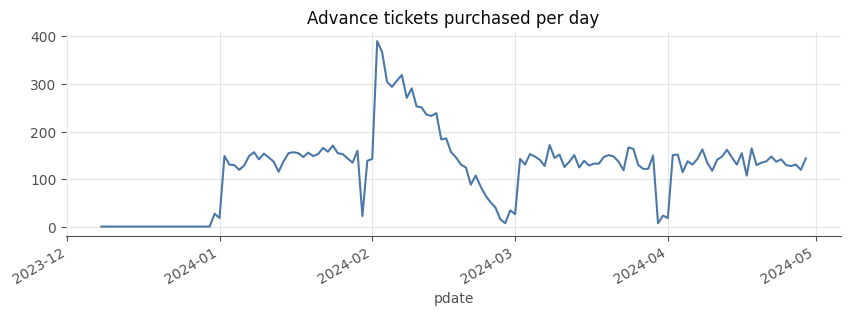

In [691]:
df["pdate"] = pd.to_datetime(df["Date of Purchase"])
adv = df[df["Ticket Type"] == "Advance"].groupby("pdate").size()
z = (adv - adv.mean()) / adv.std()
print("Advance purchases per day: mean", round(adv.mean(), 1), "| std", round(adv.std(), 1), "| days:", len(adv))
print(adv[z > 2].to_frame("purchases").assign(z=z[z > 2].round(1)))
adv.plot(figsize=(10, 3), color="#4C78A8"); plt.title("Advance tickets purchased per day"); plt.show()

In [692]:
easter = df.jd.between("2024-03-29", "2024-04-01")
print("Journey-date tickets per day: Easter window", round(df[easter].groupby("jd").size().mean()), "| other days", round(df[~easter].groupby("jd").size().mean()))
print("Avg lead days: Easter", round(df[easter].lead_days.mean(), 2), "| other", round(df[~easter].lead_days.mean(), 2))
print("Share booked 7+ days ahead (%): Easter", round((df[easter].lead_days >= 7).mean() * 100, 1), "| other", round((df[~easter].lead_days >= 7).mean() * 100, 1))

Journey-date tickets per day: Easter window 218 | other days 263
Avg lead days: Easter 0.4 | other 1.69
Share booked 7+ days ahead (%): Easter 0.2 | other 8.0


In [693]:
import networkx as nx
w = df.groupby(["Departure Station", "Arrival Destination"]).size().reset_index(name="w")
G = nx.DiGraph()
for a, b, c in w.itertuples(index=False):
    G.add_edge(a, b, weight=1 / c, volume=c)       # heavier flow = shorter distance
bc = pd.Series(nx.betweenness_centrality(G, weight="weight")).sort_values(ascending=False)
print("Stations:", G.number_of_nodes(), "| directed links:", G.number_of_edges())
print(bc.head(8).round(3))
print("Note: network built from ticket flows, not the physical rail map.")

Stations: 32 | directed links: 65
Birmingham New Street    0.146
Liverpool Lime Street    0.126
Manchester Piccadilly    0.106
London Paddington        0.087
London Euston            0.086
York                     0.048
London Kings Cross       0.040
Oxford                   0.022
dtype: float64
Note: network built from ticket flows, not the physical rail map.


In [694]:
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
y = df.disrupted.astype(int)
Xtr, Xte, ytr, yte = train_test_split(df[["route"]], y, test_size=0.25, random_state=42, stratify=y)
for name, enc in [("TargetEncoder (cross-fitted, no leakage)", TargetEncoder(cv=5, random_state=42)), ("One-hot", OneHotEncoder(handle_unknown="ignore"))]:
    m = make_pipeline(enc, LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    print(f"{name}: AUC = {roc_auc_score(yte, m.predict_proba(Xte)[:, 1]):.3f}")
print("route cardinality:", df.route.nunique(), "-> target encoding keeps 1 numeric column instead of", df.route.nunique())

TargetEncoder (cross-fitted, no leakage): AUC = 0.719
One-hot: AUC = 0.719
route cardinality: 65 -> target encoding keeps 1 numeric column instead of 65


X Questions


In [695]:
big = df.route.value_counts(); big = big[big >= 400].index
sub = df[df.route.isin(big)]
rt = sub.pivot_table(index="route", columns="month", values="disrupted", aggfunc="mean")
vol = sub.pivot_table(index="route", columns="month", values="Price", aggfunc="size")
chg = pd.DataFrame({"delay_rate_change_pp": (rt["2024-04"] - rt["2024-01"]) * 100, "tickets_change_%": (vol["2024-04"] / vol["2024-01"] - 1) * 100})
print(chg.round(1).sort_values("delay_rate_change_pp", ascending=False))
print("\ncorr(change in disruption rate, change in tickets):", round(chg.corr().iloc[0, 1], 2), "across", len(chg), "routes (Jan -> Apr)")


                                                delay_rate_change_pp  \
route                                                                  
London St Pancras -> Birmingham New Street                       6.8   
Birmingham New Street -> London St Pancras                       4.0   
London Euston -> Birmingham New Street                           4.0   
London Euston -> Manchester Piccadilly                           2.4   
London Paddington -> Reading                                     2.1   
Liverpool Lime Street -> Manchester Piccadilly                   0.7   
London Kings Cross -> York                                      -1.1   
Liverpool Lime Street -> London Euston                          -2.3   
Manchester Piccadilly -> Liverpool Lime Street                  -3.4   
London Paddington -> Oxford                                     -9.0   

                                                tickets_change_%  
route                                                             
L

In [696]:

ct = pd.crosstab(df["Ticket Class"], df.refund)
print((df.groupby("Ticket Class").refund.mean() * 100).round(2).rename("refund_rate_%"))
print("Chi-square p-value:", round(chi2_contingency(ct)[1], 3), "(p > 0.05 means no significant difference)")

Ticket Class
First Class    3.70
Standard       3.51
Name: refund_rate_%, dtype: float64
Chi-square p-value: 0.644 (p > 0.05 means no significant difference)


In [697]:
r = df.groupby("route").agg(tickets=("Price", "size"), revenue=("Price", "sum"), disruption_rate=("disrupted", "mean"))
top = r.sort_values("revenue", ascending=False).head(15).copy()
top["disruption_rate"] = (top.disruption_rate * 100).round(1)
avg = df.disrupted.mean() * 100
top["above_network_avg"] = top.disruption_rate > avg
print(f"Network disruption rate: {avg:.1f}%")
print(top)

Network disruption rate: 13.2%
                                                tickets  revenue  \
route                                                              
London Kings Cross -> York                         3922   183193   
Liverpool Lime Street -> London Euston             1097   113299   
London Paddington -> Reading                       3873    65368   
London Euston -> Manchester Piccadilly              712    61004   
London St Pancras -> Birmingham New Street         3471    52869   
London Euston -> Birmingham New Street             4209    50349   
Manchester Piccadilly -> London Euston              345    33860   
Birmingham New Street -> London St Pancras          702    19011   
Manchester Piccadilly -> Liverpool Lime Street     4628    17310   
Manchester Piccadilly -> London Paddington          144    16432   
London Paddington -> Oxford                         485    12859   
Liverpool Lime Street -> Manchester Piccadilly     3002    11950   
York -> Peterboro

In [698]:
h = df.groupby("dep_hour").agg(revenue=("Price", "sum"), disruption=("disrupted", "mean"))
h["revenue_share_%"] = (h.revenue / h.revenue.sum() * 100).round(1); h["disruption_%"] = (h.disruption * 100).round(1)
print(h.sort_values("revenue", ascending=False).head(8)[["revenue", "revenue_share_%", "disruption_%"]])
print("corr(hourly revenue, disruption rate):", round(h.revenue.corr(h.disruption), 2))
print("\nPeak vs off-peak:\n", df.groupby("peak").agg(revenue=("Price", "sum"), disruption=("disrupted", "mean")).round(3))

          revenue  revenue_share_%  disruption_%
dep_hour                                        
8          134410             18.1          40.2
7           79747             10.7           9.6
17          75751             10.2          19.4
6           65402              8.8           8.4
18          54391              7.3          10.0
16          41489              5.6          13.5
15          24670              3.3          19.2
13          23105              3.1           4.9
corr(hourly revenue, disruption rate): 0.58

Peak vs off-peak:
           revenue  disruption
peak                         
Off-Peak   334043       0.092
Peak       407878       0.179


In [699]:
loss = df[df.cancelled | df.refund]
print(loss.pivot_table(index="Reason for Delay", columns="Ticket Class", values="Price", aggfunc="sum", fill_value=0, margins=True))
print("\nTop 8 routes by lost revenue:\n", loss.groupby("route").Price.sum().sort_values(ascending=False).head(8))

Ticket Class        First Class  Standard    All
Reason for Delay                                
Signal Failure             2983     10804  13787
Staff Shortage             1576      4516   6092
Staffing                   2239     11642  13881
Technical Issue            3193     14992  18185
Traffic                    1251      7169   8420
Weather                    1380      5788   7168
Weather Conditions          862      3226   4088
All                       13484     58137  71621

Top 8 routes by lost revenue:
 route
Liverpool Lime Street -> London Euston        22175
London Kings Cross -> York                    10342
Manchester Piccadilly -> London Euston         8850
London Paddington -> Reading                   4947
London St Pancras -> Birmingham New Street     3927
London Euston -> Manchester Piccadilly         3540
London Euston -> Birmingham New Street         3032
Edinburgh Waverley -> London Kings Cross       2093
Name: Price, dtype: int64


E Questionus



In [700]:
r = df.groupby("route").Price.agg(tickets="size", avg_price="mean", std="std")
r["cv"] = r["std"] / r.avg_price
r = r[r.tickets >= 100]
print("Highest price variance (CV):\n", r.sort_values("cv", ascending=False).head(8).round(2))
print("\nLowest price variance:\n", r.sort_values("cv").head(5).round(2))

Highest price variance (CV):
                                                 tickets  avg_price    std  \
route                                                                       
Birmingham New Street -> Liverpool Lime Street      175      10.23  13.79   
London Euston -> Birmingham New Street             4209      11.96  15.24   
London St Pancras -> Birmingham New Street         3471      15.23  17.80   
Manchester Piccadilly -> Liverpool Lime Street     4628       3.74   2.63   
Reading -> Swindon                                  228      15.56  10.17   
Liverpool Lime Street -> Manchester Piccadilly     3002       3.98   2.54   
Oxford -> Bristol Temple Meads                      144      19.85  12.64   
Birmingham New Street -> London St Pancras          702      27.08  15.79   

                                                  cv  
route                                                 
Birmingham New Street -> Liverpool Lime Street  1.35  
London Euston -> Birmingham New St

In [701]:
r = df.groupby("route").agg(duration_min=("dur_min", "mean"), avg_price=("Price", "mean"), tickets=("Price", "size"))
print(r.sort_values("duration_min", ascending=False).head(8).round(1))
print("\ncorr duration vs price (route level): pearson", round(r.duration_min.corr(r.avg_price), 2), "| spearman", round(r.duration_min.corr(r.avg_price, method="spearman"), 2))
print("ticket level pearson:", round(df.dur_min.corr(df.Price), 2))

                                            duration_min  avg_price  tickets
route                                                                       
Birmingham New Street -> Edinburgh                 270.0       49.9       16
London Kings Cross -> Edinburgh Waverley           260.0       37.3      163
Edinburgh Waverley -> London Kings Cross           260.0       41.0       51
Reading -> Liverpool Lime Street                   150.0       94.1       16
Liverpool Lime Street -> London Paddington         150.0      100.0       27
Liverpool Lime Street -> London St Pancras         150.0      104.8       31
London Paddington -> Liverpool Lime Street         150.0       55.8       44
York -> Edinburgh                                  150.0       26.9      138

corr duration vs price (route level): pearson 0.61 | spearman 0.82
ticket level pearson: 0.63


In [702]:
m = df[df.dep_hour.between(6, 9)]
print(f"Morning peak (6-9am): {len(m)} tickets")
print(m.route.value_counts().head(10))



Morning peak (6-9am): 9316 tickets
route
London Paddington -> Reading                      1510
London Kings Cross -> York                        1307
Manchester Piccadilly -> Liverpool Lime Street    1098
Liverpool Lime Street -> London Euston             824
London Euston -> Birmingham New Street             758
Liverpool Lime Street -> Manchester Piccadilly     518
Birmingham New Street -> London St Pancras         510
London St Pancras -> Birmingham New Street         499
London Paddington -> Oxford                        485
London Euston -> Manchester Piccadilly             308
Name: count, dtype: int64


In [703]:
leak = df[(df.delayed & (df.delay_min > 30)) | df.cancelled]
print("Disruptions >30 min or cancelled:", len(leak), "| ticket revenue affected:", leak.Price.sum(), f"({leak.Price.sum() / df.Price.sum():.1%} of revenue)")
print("Of which refund actually requested:", leak[leak.refund].Price.sum(), f"({leak[leak.refund].Price.sum() / df.Price.sum():.1%} of revenue)")
print(leak.groupby("Journey Status").Price.agg(["size", "sum"]))

Disruptions >30 min or cancelled: 3217 | ticket revenue affected: 117320 (15.8% of revenue)
Of which refund actually requested: 13950 (1.9% of revenue)
                size    sum
Journey Status             
Cancelled       1880  45456
Delayed         1337  71864


In [704]:
from scipy.stats import levene, mannwhitneyu
d = df[df.delayed]
a, b = d[d.peak == "Peak"].delay_min, d[d.peak == "Off-Peak"].delay_min
print(f"Peak: n={len(a)} mean={a.mean():.1f} std={a.std():.1f} | Off-peak: n={len(b)} mean={b.mean():.1f} std={b.std():.1f}")
pl, pm = levene(a, b).pvalue, mannwhitneyu(a, b).pvalue
print(f"Levene (variance difference) p = {pl:.2e} -> {'significant' if pl < 0.05 else 'not significant'} at 5%")
print(f"Mann-Whitney (distribution shift) p = {pm:.2e} -> {'significant' if pm < 0.05 else 'not significant'} at 5%")

Peak: n=1551 mean=44.5 std=32.2 | Off-peak: n=741 mean=37.5 std=38.4
Levene (variance difference) p = 1.91e-01 -> not significant at 5%
Mann-Whitney (distribution shift) p = 1.78e-22 -> significant at 5%


In [705]:
df["dur_bucket"] = pd.cut(df.dur_min, [0, 45, 75, 90, 120, 300])
p = df.pivot_table(index="dur_bucket", columns="Ticket Class", values="Price", aggfunc="sum", observed=True)
p["first_to_standard"] = (p["First Class"] / p["Standard"]).round(3)
print(p)

Ticket Class  First Class  Standard  first_to_standard
dur_bucket                                            
(0, 45]              9887     37474              0.264
(45, 75]            16515     76553              0.216
(75, 90]            54750     96907              0.565
(90, 120]           44430    235625              0.189
(120, 300]          23817    145963              0.163


In [706]:
dep = df["Departure Station"].value_counts(); arr = df["Arrival Destination"].value_counts()
tr = pd.DataFrame({"departures": dep, "arrivals": arr}).fillna(0).astype(int)
tr["net_(dep-arr)"] = tr.departures - tr.arrivals
tr["role"] = np.where(tr["net_(dep-arr)"] > 0, "feeder", "destination")
print(tr.sort_values("net_(dep-arr)", ascending=False))

                       departures  arrivals  net_(dep-arr)         role
London Paddington            4500       351           4149       feeder
London Kings Cross           4229        84           4145       feeder
London Euston                4954      1567           3387       feeder
London St Pancras            3891       749           3142       feeder
Manchester Piccadilly        5650      3968           1682       feeder
Wakefield                       0        15            -15  destination
Warrington                      0        15            -15  destination
Cardiff Central                 0        16            -16  destination
Didcot                          0        48            -48  destination
Coventry                        0        65            -65  destination
London Waterloo                 0        68            -68  destination
Wolverhampton                   0       115           -115  destination
Edinburgh Waverley             51       178           -127  dest

In [707]:
from sklearn.ensemble import IsolationForest
med = df.groupby("route").Price.transform("median")
X = pd.DataFrame({"Price": df.Price, "dur_min": df.dur_min, "price_vs_route": df.Price / med})
df["anomaly"] = IsolationForest(contamination=0.01, random_state=42).fit_predict(X) == -1
print("Flagged:", df.anomaly.sum(), "of", len(df))
print(df[df.anomaly][["route", "Ticket Type", "Ticket Class", "Price", "dur_min"]].sort_values("Price", ascending=False).head(10))
print(df[df.anomaly].groupby("Ticket Class").size())

Flagged: 316 of 31653
                                            route Ticket Type Ticket Class  \
711        Manchester Piccadilly -> London Euston     Anytime  First Class   
2042       Manchester Piccadilly -> London Euston     Anytime  First Class   
11849      Manchester Piccadilly -> London Euston     Anytime  First Class   
13367            Reading -> Liverpool Lime Street     Anytime  First Class   
31434            Reading -> Liverpool Lime Street     Anytime  First Class   
22488  Liverpool Lime Street -> London Paddington     Anytime  First Class   
20279  Liverpool Lime Street -> London Paddington     Anytime  First Class   
24788      Liverpool Lime Street -> London Euston     Anytime  First Class   
24794      Liverpool Lime Street -> London Euston     Anytime  First Class   
17024      Liverpool Lime Street -> London Euston     Anytime  First Class   

       Price  dur_min  
711      267    110.0  
2042     267    110.0  
11849    267    110.0  
13367    242    150.0  

In [708]:
off = df[df.peak == "Off-Peak"]
r = off.groupby(["Ticket Class", "route"]).agg(avg_price=("Price", "mean"), tickets=("Price", "size")).reset_index()
for c, g in r.groupby("Ticket Class"):
    print(f"{c}: {len(g)} routes | corr(avg price, tickets) = {g.avg_price.corr(g.tickets):.2f}")
print("Descriptive only: price is not experimentally varied, so this is not true elasticity.")

First Class: 42 routes | corr(avg price, tickets) = -0.16
Standard: 48 routes | corr(avg price, tickets) = -0.23
Descriptive only: price is not experimentally varied, so this is not true elasticity.


Advance purchases per day: mean 138.3 | std 70.6 | days: 127
            purchases    z
pdate                     
2024-02-02        390  3.6
2024-02-03        367  3.2
2024-02-04        305  2.4
2024-02-05        294  2.2
2024-02-06        307  2.4
2024-02-07        319  2.6
2024-02-09        291  2.2


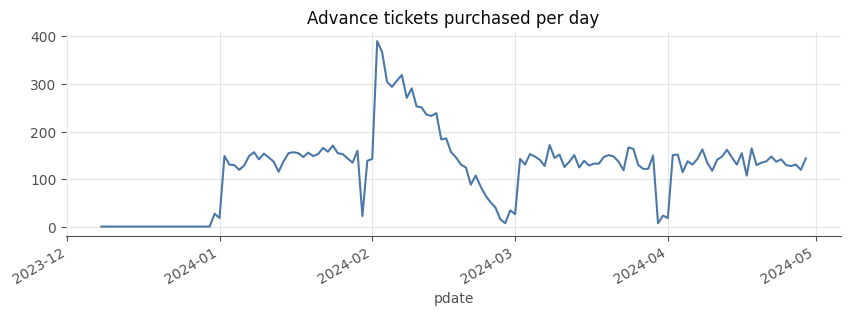

In [709]:
adv = df[df["Ticket Type"] == "Advance"].groupby("pdate").size()
z = (adv - adv.mean()) / adv.std()
print("Advance purchases per day: mean", round(adv.mean(), 1), "| std", round(adv.std(), 1), "| days:", len(adv))
print(adv[z > 2].to_frame("purchases").assign(z=z[z > 2].round(1)))
adv.plot(figsize=(10, 3), color="#4C78A8"); plt.title("Advance tickets purchased per day"); plt.show()

In [710]:
easter = df.jd.between("2024-03-29", "2024-04-01")
print("Journey-date tickets per day: Easter window", round(df[easter].groupby("jd").size().mean()), "| other days", round(df[~easter].groupby("jd").size().mean()))
print("Avg lead days: Easter", round(df[easter].lead_days.mean(), 2), "| other", round(df[~easter].lead_days.mean(), 2))
print("Share booked 7+ days ahead (%): Easter", round((df[easter].lead_days >= 7).mean() * 100, 1), "| other", round((df[~easter].lead_days >= 7).mean() * 100, 1))

Journey-date tickets per day: Easter window 218 | other days 263
Avg lead days: Easter 0.4 | other 1.69
Share booked 7+ days ahead (%): Easter 0.2 | other 8.0


In [711]:
import networkx as nx
w = df.groupby(["Departure Station", "Arrival Destination"]).size().reset_index(name="w")
G = nx.DiGraph()
for a, b, c in w.itertuples(index=False):
    G.add_edge(a, b, weight=1 / c, volume=c)       # heavier flow = shorter distance
bc = pd.Series(nx.betweenness_centrality(G, weight="weight")).sort_values(ascending=False)
print("Stations:", G.number_of_nodes(), "| directed links:", G.number_of_edges())
print(bc.head(8).round(3))
print("Note: network built from ticket flows, not the physical rail map.")

Stations: 32 | directed links: 65
Birmingham New Street    0.146
Liverpool Lime Street    0.126
Manchester Piccadilly    0.106
London Paddington        0.087
London Euston            0.086
York                     0.048
London Kings Cross       0.040
Oxford                   0.022
dtype: float64
Note: network built from ticket flows, not the physical rail map.


In [712]:
y = df.disrupted.astype(int)
Xtr, Xte, ytr, yte = train_test_split(df[["route"]], y, test_size=0.25, random_state=42, stratify=y)
for name, enc in [("TargetEncoder (cross-fitted, no leakage)", TargetEncoder(cv=5, random_state=42)), ("One-hot", OneHotEncoder(handle_unknown="ignore"))]:
    m = make_pipeline(enc, LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    print(f"{name}: AUC = {roc_auc_score(yte, m.predict_proba(Xte)[:, 1]):.3f}")
print("route cardinality:", df.route.nunique(), "-> target encoding keeps 1 numeric column instead of", df.route.nunique())


TargetEncoder (cross-fitted, no leakage): AUC = 0.719
One-hot: AUC = 0.719
route cardinality: 65 -> target encoding keeps 1 numeric column instead of 65
